# Classificazione del macroruolo dei giocatori FC25

## Previsione di attaccanti, centrocampisti e difensori

L'obiettivo è prevedere il macroruolo del giocatore attraverso le sue statistiche tecniche. Il problema è multiclasse e comprende tre categorie:

- attaccante;
- centrocampista;
- difensore.

Per evitare che il modello riceva informazioni troppo vicine alla risposta, non vengono utilizzate la posizione principale, le posizioni alternative né le variabili costruite a partire da esse. I modelli vengono confrontati con un riferimento semplice che assegna sempre la classe più frequente.

In [1]:
from pathlib import Path
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.environ['LOKY_MAX_CPU_COUNT'] = '1'

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

sns.set_theme(style='whitegrid', context='talk')
plt.rcParams.update({
    'figure.figsize': (14, 7),
    'figure.dpi': 110,
    'axes.titleweight': 'bold',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'legend.frameon': False,
})

DATA_PATH = Path('../data/puliti/movimento_puliti.csv')
FIG_DIR = Path('figure_classificazione')
FIG_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH)
print(f'Giocatori di movimento caricati: {len(df):,}')

Giocatori di movimento caricati: 15,738


## 1. Costruzione della variabile da prevedere

Il macroruolo deriva esclusivamente dalla posizione principale. Dopo aver creato la variabile da prevedere, `Position` non viene inserita tra le caratteristiche del modello.

,Giocatori,Percentuale
Macro_Ruolo,,
Attaccante,3210,20.4%
Centrocampista,6606,42.0%
Difensore,5922,37.6%


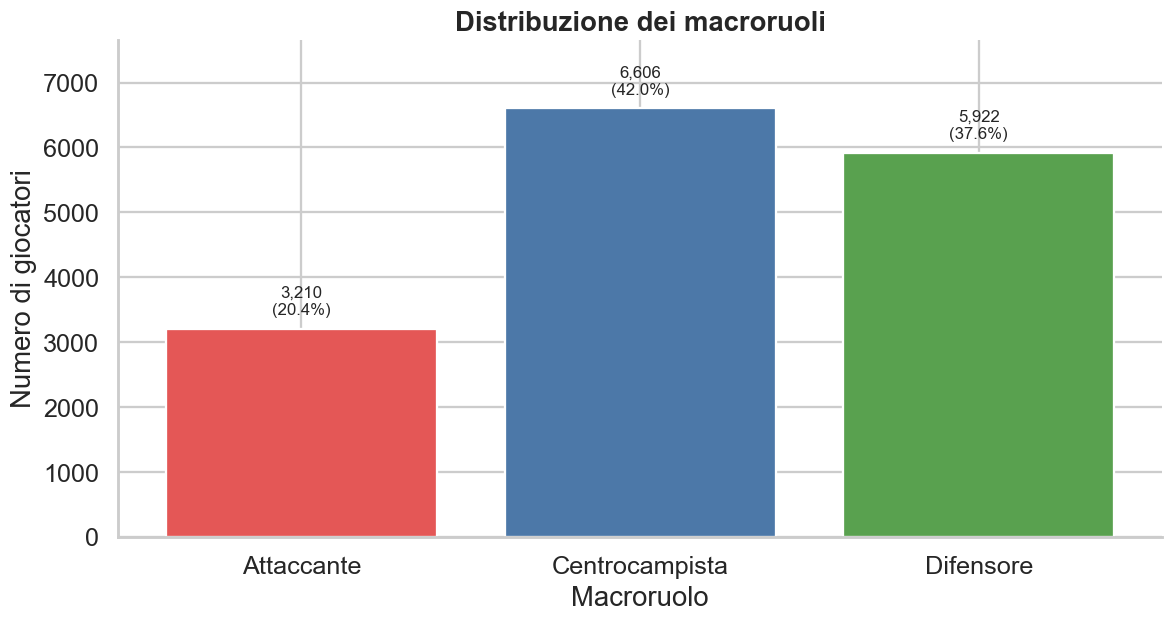

In [2]:
ATTACK_POSITIONS = {'ST', 'CF', 'LW', 'RW', 'RF', 'LF'}
MIDFIELD_POSITIONS = {'CM', 'CDM', 'CAM', 'LM', 'RM'}
DEFENCE_POSITIONS = {'CB', 'LB', 'RB', 'LWB', 'RWB'}

def macro_role(position):
    if position in ATTACK_POSITIONS:
        return 'Attaccante'
    if position in MIDFIELD_POSITIONS:
        return 'Centrocampista'
    if position in DEFENCE_POSITIONS:
        return 'Difensore'
    return np.nan

df_classification = df.copy()
df_classification['Macro_Ruolo'] = df_classification['Position'].map(macro_role)
df_classification = (
    df_classification.dropna(subset=['Macro_Ruolo'])
    .reset_index(drop=True)
)

CLASS_ORDER = ['Attaccante', 'Centrocampista', 'Difensore']
class_counts = (
    df_classification['Macro_Ruolo']
    .value_counts()
    .reindex(CLASS_ORDER)
)
class_percentages = class_counts / class_counts.sum() * 100

class_table = pd.DataFrame({
    'Giocatori': class_counts,
    'Percentuale': class_percentages,
})
display(class_table.style.format({'Percentuale': '{:.1f}%'}))

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.bar(
    class_counts.index,
    class_counts.values,
    color=['#e45756', '#4c78a8', '#59a14f'],
)
ax.set_title('Distribuzione dei macroruoli')
ax.set_xlabel('Macroruolo')
ax.set_ylabel('Numero di giocatori')
ax.set_ylim(0, class_counts.max() * 1.16)

for bar, count, percentage in zip(bars, class_counts, class_percentages):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + class_counts.max() * 0.025,
        f'{count:,}\n({percentage:.1f}%)',
        ha='center',
        va='bottom',
        fontsize=11,
    )

fig.tight_layout()
fig.savefig(FIG_DIR / '01_distribuzione_macroruoli.png', dpi=300, bbox_inches='tight')
plt.show()

## 2. Scelta delle caratteristiche

Vengono utilizzate 29 statistiche tecniche dettagliate. Sono escluse:

- `Position` e tutte le variabili derivate dalle posizioni alternative, perché anticiperebbero la risposta;
- `OVR`, perché misura il livello generale e non una caratteristica specifica del ruolo;
- le statistiche aggregate `PAC`, `SHO`, `PAS`, `DRI`, `DEF`, `PHY`, per non duplicare l'informazione già contenuta nelle statistiche dettagliate;
- piede preferito, età, nazionalità, squadra e playstyle, per mantenere l'analisi concentrata sulle capacità tecniche.

In [3]:
technical_features = [
    'Acceleration', 'Sprint Speed',
    'Positioning', 'Finishing', 'Shot Power', 'Long Shots', 'Volleys', 'Penalties',
    'Vision', 'Crossing', 'Free Kick Accuracy', 'Short Passing', 'Long Passing', 'Curve',
    'Dribbling', 'Agility', 'Balance', 'Reactions', 'Ball Control', 'Composure',
    'Interceptions', 'Heading Accuracy', 'Def Awareness', 'Standing Tackle', 'Sliding Tackle',
    'Jumping', 'Stamina', 'Strength', 'Aggression',
]

missing_columns = [
    column for column in technical_features
    if column not in df_classification.columns
]
if missing_columns:
    raise ValueError(f'Colonne mancanti: {missing_columns}')

X = df_classification[technical_features].copy()
y = df_classification['Macro_Ruolo'].copy()

print(f'Giocatori utilizzati: {len(X):,}')
print(f'Caratteristiche utilizzate: {X.shape[1]}')
print(f'Valori mancanti: {int(X.isna().sum().sum())}')

Giocatori utilizzati: 15,738
Caratteristiche utilizzate: 29
Valori mancanti: 0


## 3. Suddivisione dei dati e modello di riferimento

Il 70% dei giocatori viene utilizzato per l'addestramento e il 30% per la valutazione finale. La stratificazione conserva le proporzioni dei tre macroruoli.

Il modello di riferimento assegna sempre la classe più frequente. Serve a verificare che i modelli addestrati imparino una struttura reale e non si limitino a sfruttare la distribuzione delle classi.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y,
)

print(f'Giocatori nel training set: {len(X_train):,}')
print(f'Giocatori nel test set: {len(X_test):,}')

baseline_class = y_train.value_counts().idxmax()
baseline_train_pred = np.full(len(y_train), baseline_class)
baseline_test_pred = np.full(len(y_test), baseline_class)

print(f'Classe sempre prevista dal riferimento: {baseline_class}')
print(f'Accuracy del riferimento: {accuracy_score(y_test, baseline_test_pred):.2%}')

Giocatori nel training set: 11,016
Giocatori nel test set: 4,722
Classe sempre prevista dal riferimento: Centrocampista
Accuracy del riferimento: 41.97%


## 4. Addestramento dei modelli

Vengono confrontati due modelli affrontati nel corso:

- regressione logistica multiclasse;
- Random Forest.

La standardizzazione viene stimata esclusivamente sul training set ed è applicata alla regressione logistica. Random Forest utilizza invece i valori originali, perché gli alberi decisionali non richiedono lo scaling.

In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42,
)
logistic_model.fit(X_train_scaled, y_train)

forest_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
)
forest_model.fit(X_train, y_train)

predictions = {
    'Riferimento': {
        'train': baseline_train_pred,
        'test': baseline_test_pred,
    },
    'Regressione logistica': {
        'train': logistic_model.predict(X_train_scaled),
        'test': logistic_model.predict(X_test_scaled),
    },
    'Random Forest': {
        'train': forest_model.predict(X_train),
        'test': forest_model.predict(X_test),
    },
}

print('Addestramento completato.')

Addestramento completato.


## 5. Confronto delle prestazioni

Oltre all'accuracy vengono calcolate precision, recall e F1-score con media macro. La media macro assegna lo stesso peso ai tre ruoli, indipendentemente dalla loro numerosità.

,Accuracy training,Accuracy test,Precision macro,Recall macro,F1-score macro
Modello,,,,,
Riferimento,0.4198,0.4197,0.1399,0.3333,0.1971
Regressione logistica,0.8706,0.8770,0.8763,0.8638,0.8694
Random Forest,1.0000,0.8820,0.8818,0.8635,0.8713


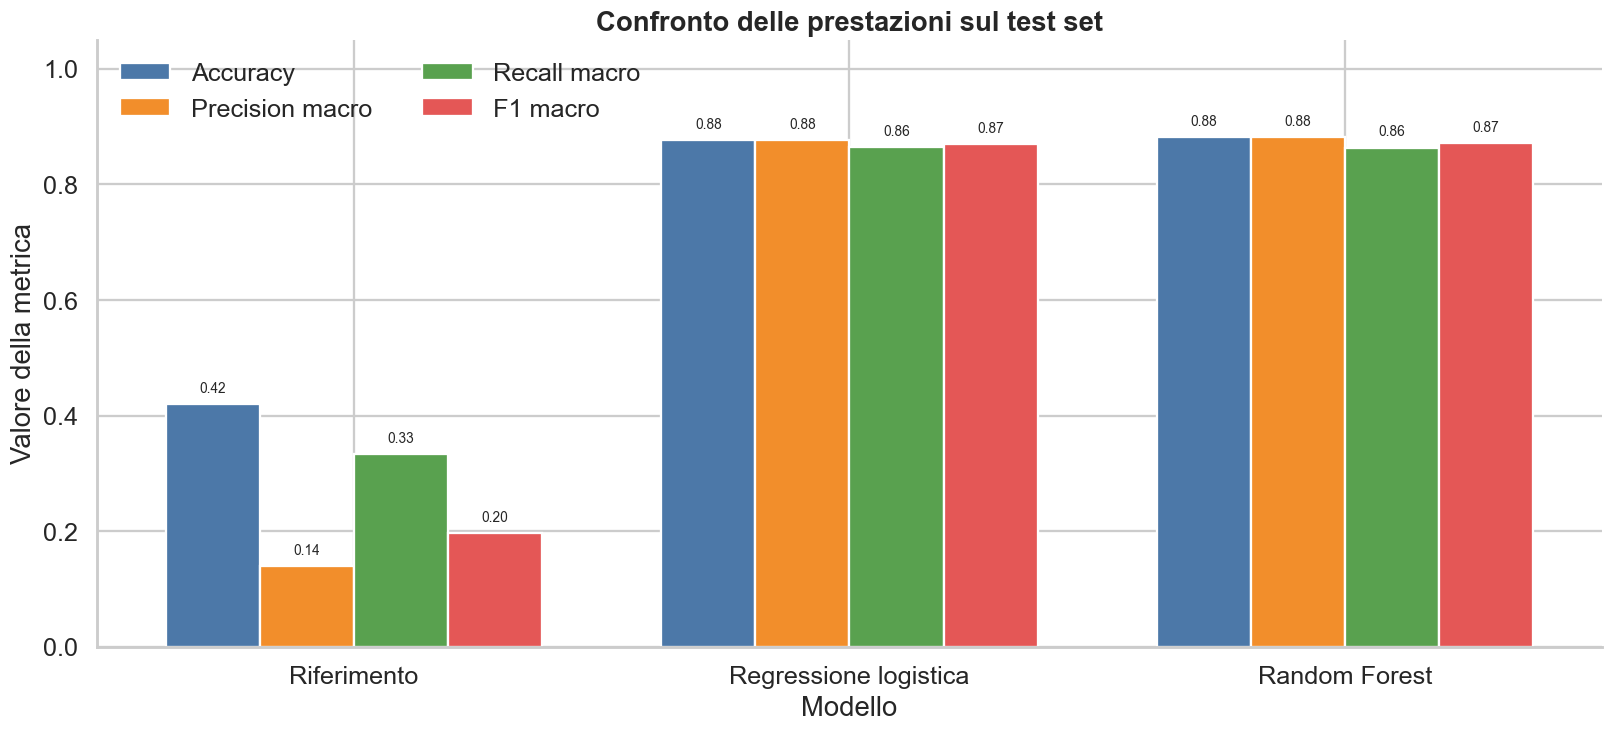

In [6]:
metric_rows = []

for model_name, model_predictions in predictions.items():
    y_pred_train = model_predictions['train']
    y_pred_test = model_predictions['test']
    metric_rows.append({
        'Modello': model_name,
        'Accuracy training': accuracy_score(y_train, y_pred_train),
        'Accuracy test': accuracy_score(y_test, y_pred_test),
        'Precision macro': precision_score(
            y_test, y_pred_test, average='macro', zero_division=0
        ),
        'Recall macro': recall_score(
            y_test, y_pred_test, average='macro', zero_division=0
        ),
        'F1-score macro': f1_score(
            y_test, y_pred_test, average='macro', zero_division=0
        ),
    })

metrics_table = pd.DataFrame(metric_rows).set_index('Modello')
display(metrics_table.style.format('{:.4f}').highlight_max(axis=0, color='#c7e9c0'))

plot_metrics = [
    'Accuracy test',
    'Precision macro',
    'Recall macro',
    'F1-score macro',
]
metric_labels = ['Accuracy', 'Precision macro', 'Recall macro', 'F1 macro']

fig, ax = plt.subplots(figsize=(15, 7))
x_positions = np.arange(len(metrics_table))
bar_width = 0.19
colors = ['#4c78a8', '#f28e2b', '#59a14f', '#e45756']

for index, (metric, label, color) in enumerate(
    zip(plot_metrics, metric_labels, colors)
):
    bars = ax.bar(
        x_positions + (index - 1.5) * bar_width,
        metrics_table[metric],
        width=bar_width,
        label=label,
        color=color,
    )
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.015,
            f'{bar.get_height():.2f}',
            ha='center',
            va='bottom',
            fontsize=9,
        )

ax.set_title('Confronto delle prestazioni sul test set')
ax.set_xlabel('Modello')
ax.set_ylabel('Valore della metrica')
ax.set_xticks(x_positions)
ax.set_xticklabels(metrics_table.index)
ax.set_ylim(0, 1.05)
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / '02_confronto_modelli.png', dpi=300, bbox_inches='tight')
plt.show()

### Lettura del confronto

Il riferimento raggiunge circa il 42% di accuracy perché assegna tutti i giocatori alla classe dei centrocampisti. Entrambi i modelli addestrati superano nettamente questo valore.

Random Forest ottiene risultati leggermente superiori sul test set, ma raggiunge il 100% sul training set. La regressione logistica è quasi equivalente sul test e presenta uno scarto molto più contenuto fra addestramento e valutazione. Per questo i risultati di entrambi vengono mantenuti, senza dichiarare un vincitore sulla sola base di pochi decimi percentuali.

## 6. Matrici di confusione

Le matrici sono normalizzate per riga: ogni valore rappresenta la percentuale di giocatori di un determinato ruolo assegnata alle tre classi possibili.

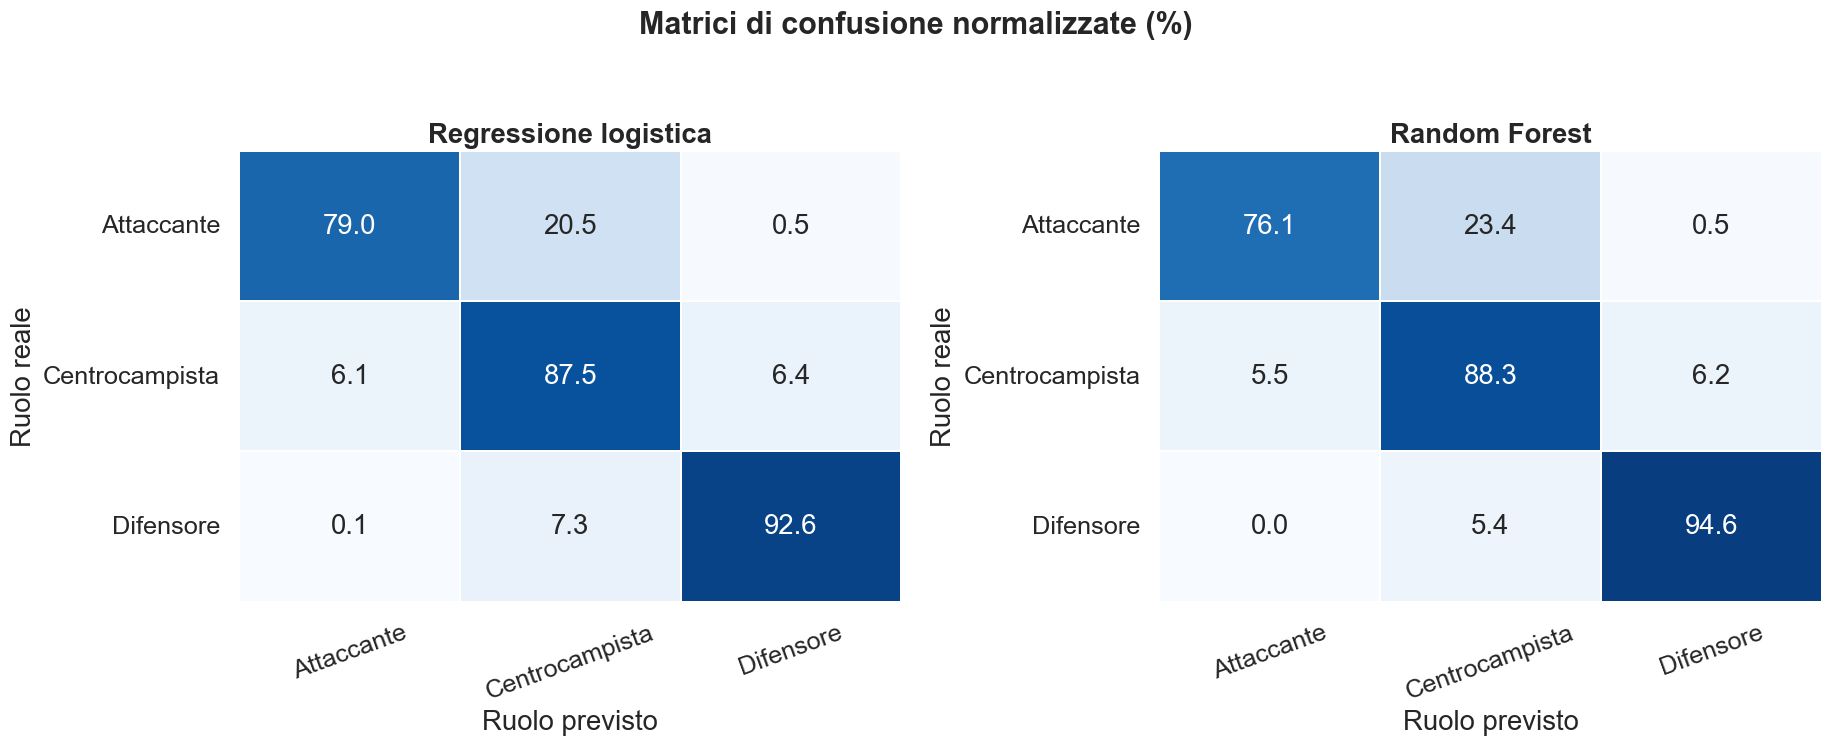

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

for ax, model_name, title in zip(
    axes,
    ['Regressione logistica', 'Random Forest'],
    ['Regressione logistica', 'Random Forest'],
):
    matrix = confusion_matrix(
        y_test,
        predictions[model_name]['test'],
        labels=CLASS_ORDER,
        normalize='true',
    )
    sns.heatmap(
        matrix * 100,
        annot=True,
        fmt='.1f',
        cmap='Blues',
        vmin=0,
        vmax=100,
        linewidths=1,
        cbar=False,
        xticklabels=CLASS_ORDER,
        yticklabels=CLASS_ORDER,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel('Ruolo previsto')
    ax.set_ylabel('Ruolo reale')
    ax.tick_params(axis='x', rotation=20)
    ax.tick_params(axis='y', rotation=0)

fig.suptitle('Matrici di confusione normalizzate (%)', fontsize=20, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(FIG_DIR / '03_matrici_confusione.png', dpi=300, bbox_inches='tight')
plt.show()

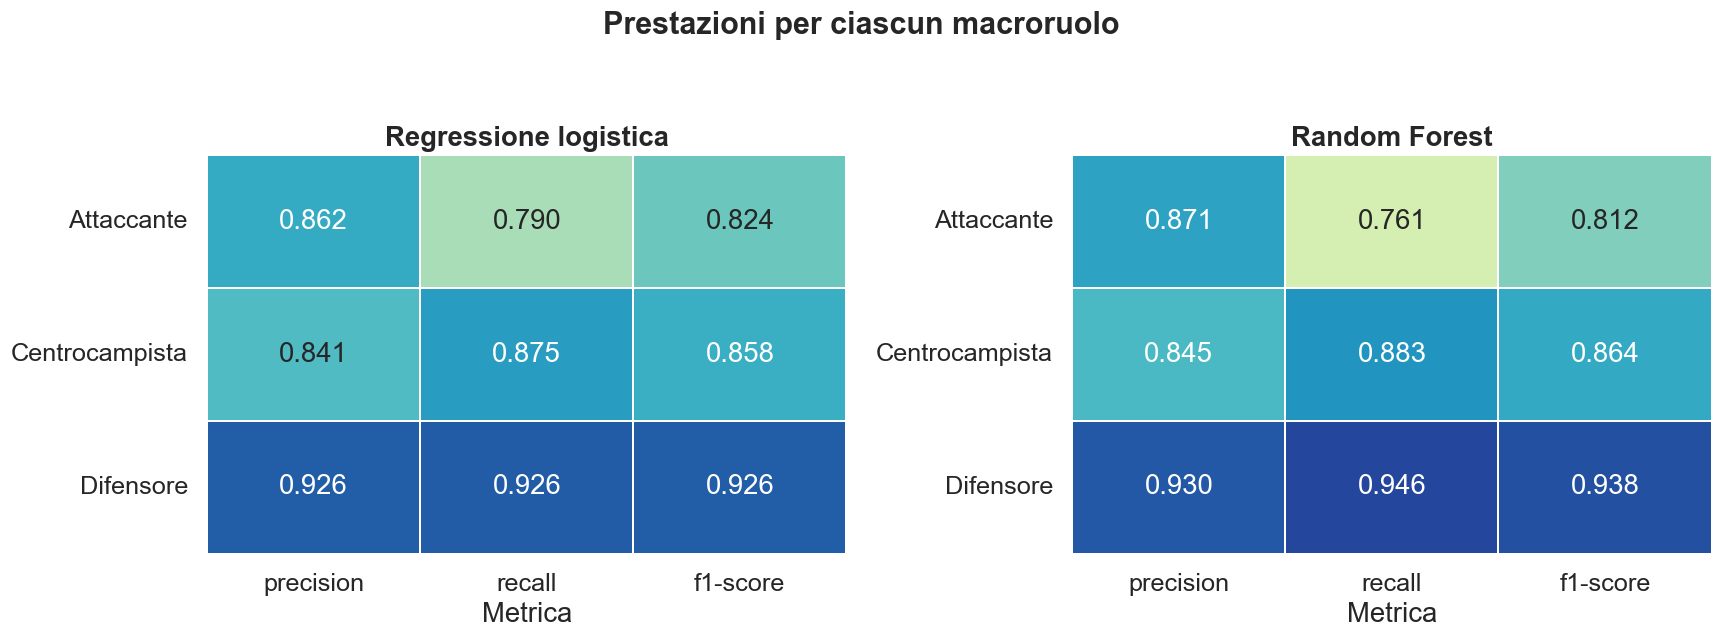

Regressione logistica


,precision,recall,f1-score
Attaccante,0.862,0.790,0.824
Centrocampista,0.841,0.875,0.858
Difensore,0.926,0.926,0.926


Random Forest


,precision,recall,f1-score
Attaccante,0.871,0.761,0.812
Centrocampista,0.845,0.883,0.864
Difensore,0.930,0.946,0.938


In [8]:
report_tables = {}

for model_name in ['Regressione logistica', 'Random Forest']:
    report = classification_report(
        y_test,
        predictions[model_name]['test'],
        labels=CLASS_ORDER,
        output_dict=True,
        zero_division=0,
    )
    report_tables[model_name] = (
        pd.DataFrame(report).T
        .loc[CLASS_ORDER, ['precision', 'recall', 'f1-score']]
    )

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, model_name in zip(axes, report_tables):
    sns.heatmap(
        report_tables[model_name],
        annot=True,
        fmt='.3f',
        cmap='YlGnBu',
        vmin=0.70,
        vmax=1.00,
        linewidths=1,
        cbar=False,
        ax=ax,
    )
    ax.set_title(model_name)
    ax.set_xlabel('Metrica')
    ax.set_ylabel('')
    ax.tick_params(axis='y', rotation=0)

fig.suptitle('Prestazioni per ciascun macroruolo', fontsize=20, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(FIG_DIR / '04_metriche_per_ruolo.png', dpi=300, bbox_inches='tight')
plt.show()

for model_name, report_table in report_tables.items():
    print(model_name)
    display(report_table.style.format('{:.3f}'))

## 7. Interpretazione dei modelli

Poiché le caratteristiche sono standardizzate, i coefficienti della regressione logistica possono essere confrontati fra loro. Un coefficiente positivo aumenta il punteggio associato alla classe indicata, mentre un coefficiente negativo lo riduce.

Per Random Forest viene mostrata l'importanza assegnata alle variabili durante la costruzione degli alberi. Questa misura descrive l'uso delle caratteristiche nel modello, ma non stabilisce un rapporto causale.

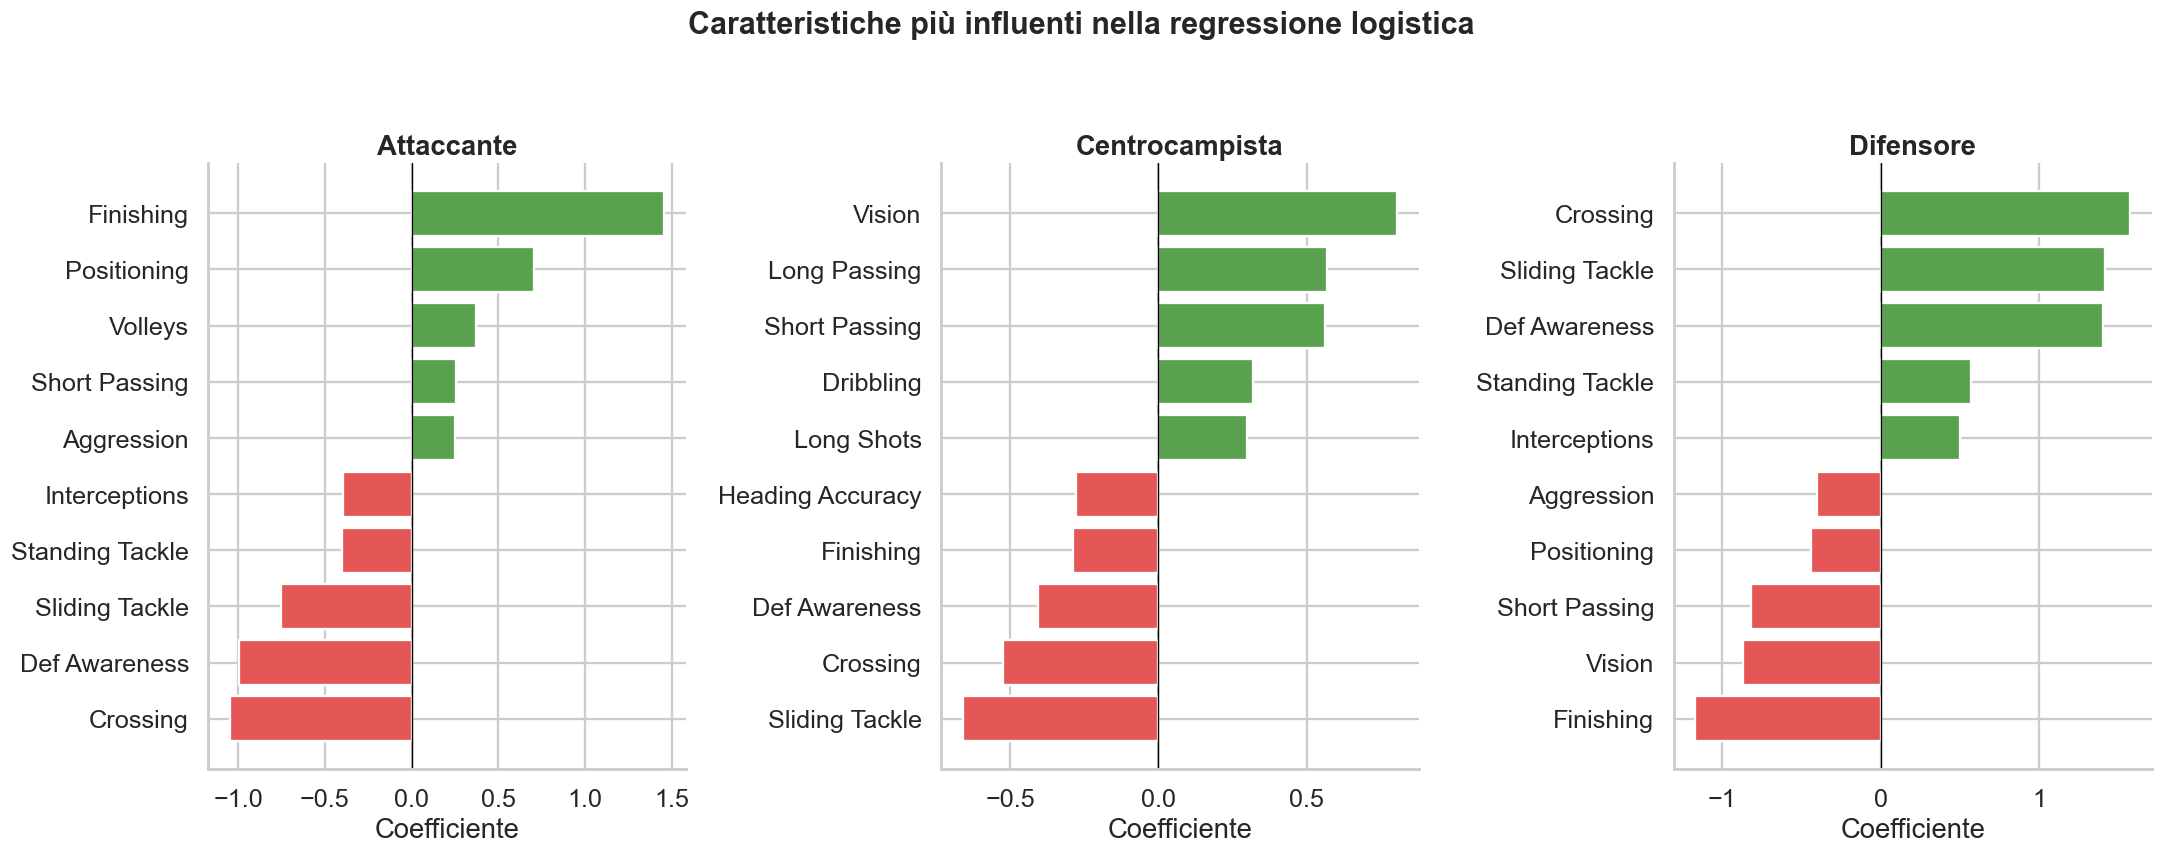

In [9]:
coefficient_table = pd.DataFrame(
    logistic_model.coef_,
    index=logistic_model.classes_,
    columns=technical_features,
)

fig, axes = plt.subplots(1, 3, figsize=(20, 8))

for ax, role in zip(axes, CLASS_ORDER):
    coefficients = coefficient_table.loc[role]
    selected_features = coefficients.abs().nlargest(10).index
    selected = coefficients.loc[selected_features].sort_values()
    bar_colors = [
        '#59a14f' if value > 0 else '#e45756'
        for value in selected
    ]
    ax.barh(selected.index, selected.values, color=bar_colors)
    ax.axvline(0, color='black', linewidth=0.9)
    ax.set_title(role)
    ax.set_xlabel('Coefficiente')

fig.suptitle(
    'Caratteristiche più influenti nella regressione logistica',
    fontsize=20,
    fontweight='bold',
)
fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(FIG_DIR / '05_coefficienti_logistica.png', dpi=300, bbox_inches='tight')
plt.show()

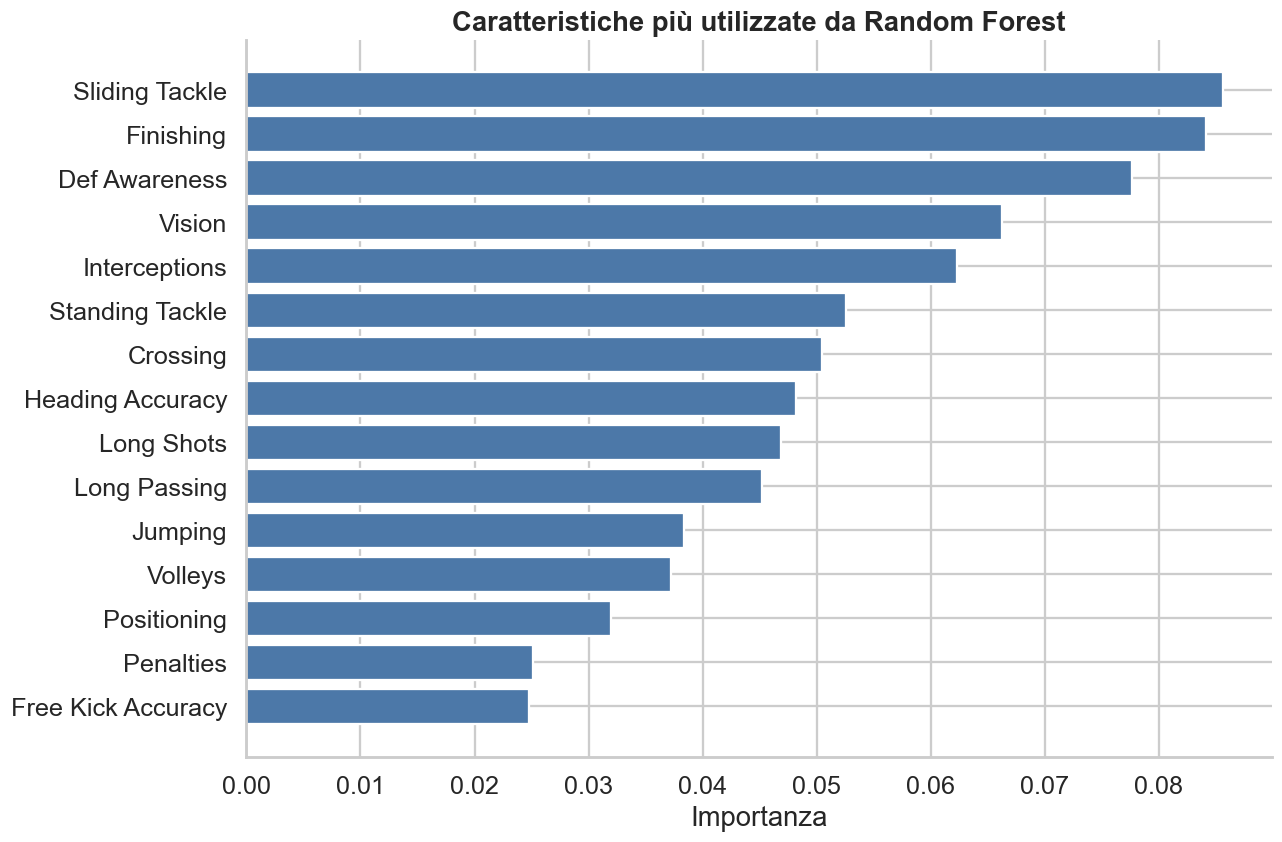

,Importanza
Sliding Tackle,0.0856
Finishing,0.0841
Def Awareness,0.0777
Vision,0.0662
Interceptions,0.0623
Standing Tackle,0.0526
Crossing,0.0505
Heading Accuracy,0.0482
Long Shots,0.0469
Long Passing,0.0452


In [10]:
forest_importance = (
    pd.Series(forest_model.feature_importances_, index=technical_features)
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(forest_importance.index, forest_importance.values, color='#4c78a8')
ax.set_title('Caratteristiche più utilizzate da Random Forest')
ax.set_xlabel('Importanza')
ax.set_ylabel('')
fig.tight_layout()
fig.savefig(FIG_DIR / '06_importanza_random_forest.png', dpi=300, bbox_inches='tight')
plt.show()

display(
    forest_importance.sort_values(ascending=False)
    .rename('Importanza')
    .to_frame()
    .style.format('{:.4f}')
)

## 8. Esperimento di feature engineering

Finora ogni statistica tecnica è stata fornita separatamente al modello. In questa sezione le 29 statistiche vengono trasformate in sei indicatori sintetici e interpretabili dal punto di vista calcistico:

- velocità;
- finalizzazione;
- costruzione del gioco;
- controllo di palla;
- difesa;
- fisicità.

Ogni indicatore è la media delle statistiche appartenenti alla stessa area. Tutte le 29 variabili originali compaiono in uno e un solo indicatore: non vengono quindi selezionate sulla base del risultato da prevedere. Inoltre, altezza e peso vengono estratti dalle rispettive colonne testuali e convertiti in valori numerici.

Il confronto mantiene invariati giocatori di training e test, algoritmo e criterio di valutazione. Si considerano tre rappresentazioni: le 29 statistiche originali, i soli sei indici tecnici e i sei indici arricchiti con altezza e peso. Le variabili originali e i relativi indici non vengono usati insieme, per evitare di duplicare la stessa informazione.


In [11]:
FEATURE_GROUPS = {
    'Velocità': ['Acceleration', 'Sprint Speed'],
    'Finalizzazione': [
        'Positioning', 'Finishing', 'Shot Power',
        'Long Shots', 'Volleys', 'Penalties',
    ],
    'Costruzione': [
        'Vision', 'Crossing', 'Free Kick Accuracy',
        'Short Passing', 'Long Passing', 'Curve',
    ],
    'Controllo': [
        'Dribbling', 'Agility', 'Balance',
        'Reactions', 'Ball Control', 'Composure',
    ],
    'Difesa': [
        'Interceptions', 'Heading Accuracy', 'Def Awareness',
        'Standing Tackle', 'Sliding Tackle',
    ],
    'Fisicità': ['Jumping', 'Stamina', 'Strength', 'Aggression'],
}

grouped_source_features = [
    feature
    for group_features in FEATURE_GROUPS.values()
    for feature in group_features
]
if set(grouped_source_features) != set(technical_features):
    raise ValueError('Gli indici non coprono esattamente le 29 statistiche originali.')

engineered_data = pd.DataFrame(index=df_classification.index)
for indicator, source_features in FEATURE_GROUPS.items():
    engineered_data[indicator] = df_classification[source_features].mean(axis=1)

engineered_data['Altezza (cm)'] = pd.to_numeric(
    df_classification['Height'].str.extract(r'^(\d+)')[0],
    errors='coerce',
)
engineered_data['Peso (kg)'] = pd.to_numeric(
    df_classification['Weight'].str.extract(r'^(\d+)')[0],
    errors='coerce',
)

if engineered_data.isna().any().any():
    missing = engineered_data.isna().sum()
    raise ValueError(
        f'Valori mancanti dopo la costruzione delle variabili:\n{missing[missing > 0]}'
    )

feature_definition_table = pd.DataFrame({
    'Indicatore': list(FEATURE_GROUPS),
    'Numero di statistiche': [len(values) for values in FEATURE_GROUPS.values()],
    'Statistiche di origine': [', '.join(values) for values in FEATURE_GROUPS.values()],
})
display(feature_definition_table.style.hide(axis='index'))

print(f'Variabili originali riassunte: {len(grouped_source_features)}')
print(f'Indicatori tecnici costruiti: {len(FEATURE_GROUPS)}')
print('Altezza e peso convertiti correttamente in formato numerico.')


Indicatore,Numero di statistiche,Statistiche di origine
Velocità,2,"Acceleration, Sprint Speed"
Finalizzazione,6,"Positioning, Finishing, Shot Power, Long Shots, Volleys, Penalties"
Costruzione,6,"Vision, Crossing, Free Kick Accuracy, Short Passing, Long Passing, Curve"
Controllo,6,"Dribbling, Agility, Balance, Reactions, Ball Control, Composure"
Difesa,5,"Interceptions, Heading Accuracy, Def Awareness, Standing Tackle, Sliding Tackle"
Fisicità,4,"Jumping, Stamina, Strength, Aggression"


Variabili originali riassunte: 29
Indicatori tecnici costruiti: 6
Altezza e peso convertiti correttamente in formato numerico.


### Profili medi dei macroruoli

Per rendere confrontabili variabili espresse su scale diverse, il grafico riporta medie standardizzate. Un valore positivo indica che, per quella caratteristica, il ruolo si colloca sopra la media complessiva dei giocatori; un valore negativo indica una posizione sotto la media. Il grafico è descrittivo e non viene usato per addestrare i modelli.


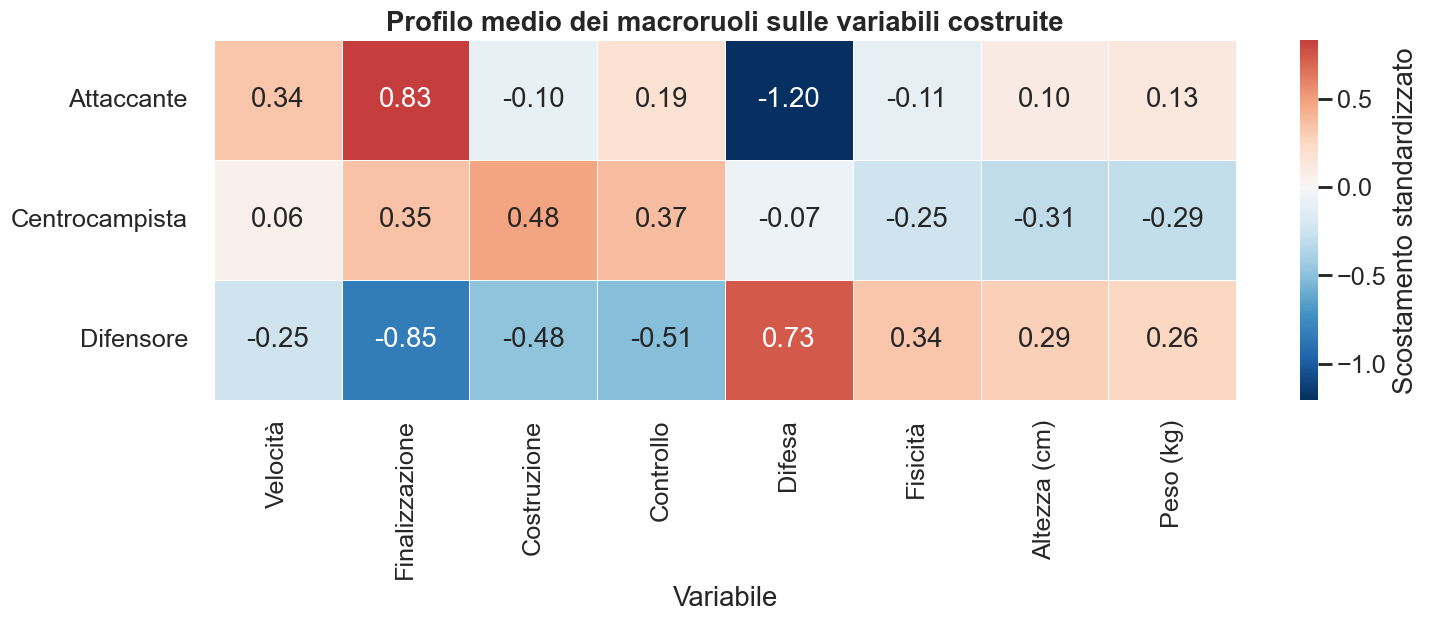

In [12]:
profile_features = list(FEATURE_GROUPS) + ['Altezza (cm)', 'Peso (kg)']
standardized_profiles = (
    engineered_data[profile_features]
    - engineered_data[profile_features].mean()
) / engineered_data[profile_features].std(ddof=0)
standardized_profiles['Macro_Ruolo'] = y

role_profiles = (
    standardized_profiles
    .groupby('Macro_Ruolo')[profile_features]
    .mean()
    .reindex(CLASS_ORDER)
)

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(
    role_profiles,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    linewidths=0.5,
    cbar_kws={'label': 'Scostamento standardizzato'},
    ax=ax,
)
ax.set_title('Profilo medio dei macroruoli sulle variabili costruite')
ax.set_xlabel('Variabile')
ax.set_ylabel('')
ax.tick_params(axis='y', rotation=0, pad=8)
fig.tight_layout()
fig.savefig(
    FIG_DIR / '11_profili_feature_engineering.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()


### Confronto a parità di modello

La regressione logistica viene riaddestrata sulle due nuove rappresentazioni. La standardizzazione è nuovamente stimata soltanto sul training set. Il modello con 29 statistiche già addestrato costituisce il termine di confronto: in questo modo si misura l'effetto della trasformazione delle variabili, non quello di un algoritmo differente.


,Numero variabili,Accuracy,Precision macro,Recall macro,F1-score macro
Rappresentazione,,,,,
29 statistiche originali,29,0.8770,0.8763,0.8638,0.8694
6 indici tecnici,6,0.8230,0.8285,0.8141,0.8205
6 indici + altezza/peso,8,0.8232,0.8282,0.8145,0.8206


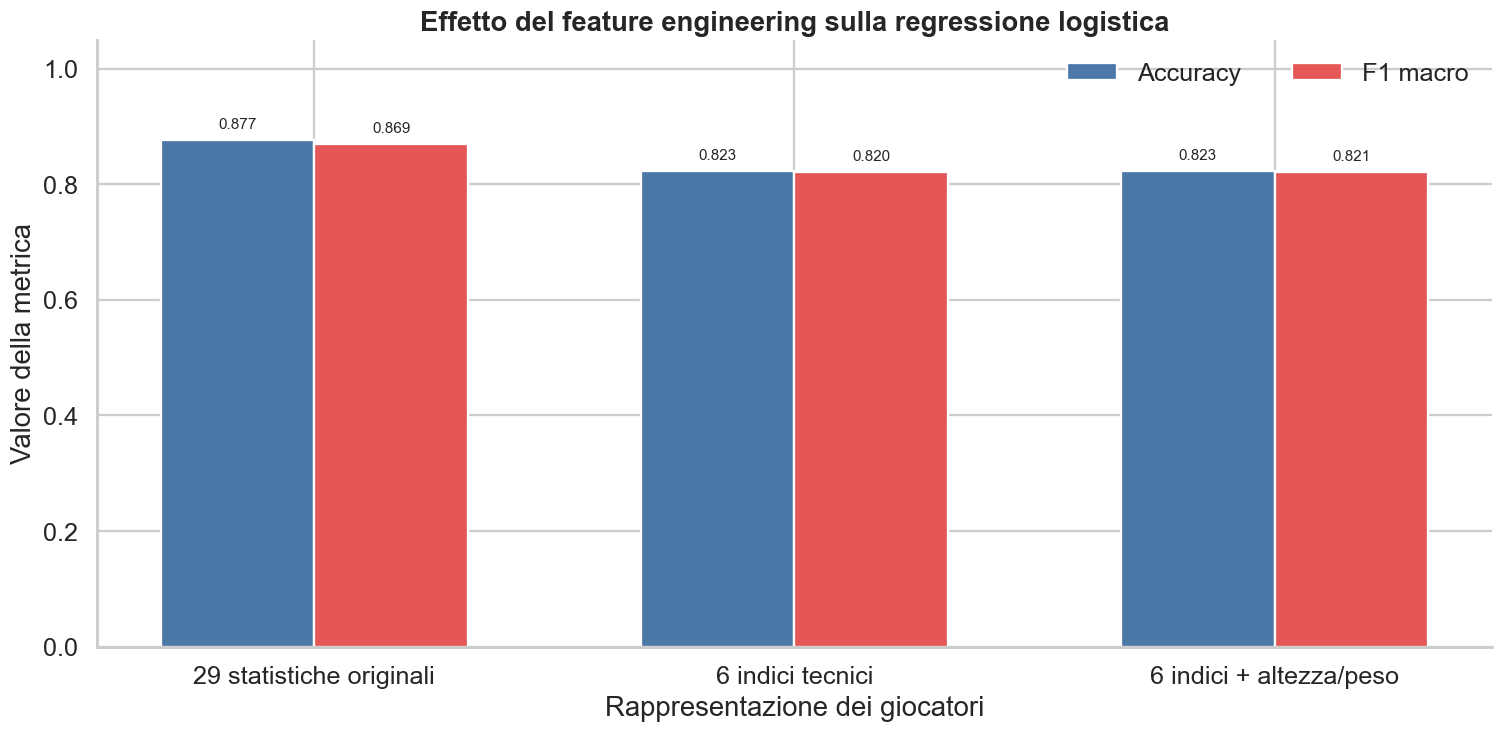

In [13]:
technical_indicator_names = list(FEATURE_GROUPS)
enriched_indicator_names = technical_indicator_names + ['Altezza (cm)', 'Peso (kg)']

X_indicators = engineered_data[technical_indicator_names]
X_enriched = engineered_data[enriched_indicator_names]

X_indicators_train = X_indicators.loc[X_train.index]
X_indicators_test = X_indicators.loc[X_test.index]
X_enriched_train = X_enriched.loc[X_train.index]
X_enriched_test = X_enriched.loc[X_test.index]

indicator_scaler = StandardScaler()
X_indicators_train_scaled = indicator_scaler.fit_transform(X_indicators_train)
X_indicators_test_scaled = indicator_scaler.transform(X_indicators_test)

enriched_scaler = StandardScaler()
X_enriched_train_scaled = enriched_scaler.fit_transform(X_enriched_train)
X_enriched_test_scaled = enriched_scaler.transform(X_enriched_test)

indicator_model = LogisticRegression(max_iter=2000, random_state=42)
indicator_model.fit(X_indicators_train_scaled, y_train)

enriched_model = LogisticRegression(max_iter=2000, random_state=42)
enriched_model.fit(X_enriched_train_scaled, y_train)

feature_engineering_predictions = {
    '29 statistiche originali': predictions['Regressione logistica']['test'],
    '6 indici tecnici': indicator_model.predict(X_indicators_test_scaled),
    '6 indici + altezza/peso': enriched_model.predict(X_enriched_test_scaled),
}

feature_engineering_rows = []
for representation, y_pred in feature_engineering_predictions.items():
    feature_engineering_rows.append({
        'Rappresentazione': representation,
        'Numero variabili': {
            '29 statistiche originali': len(technical_features),
            '6 indici tecnici': len(technical_indicator_names),
            '6 indici + altezza/peso': len(enriched_indicator_names),
        }[representation],
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision macro': precision_score(
            y_test, y_pred, average='macro', zero_division=0
        ),
        'Recall macro': recall_score(
            y_test, y_pred, average='macro', zero_division=0
        ),
        'F1-score macro': f1_score(
            y_test, y_pred, average='macro', zero_division=0
        ),
    })

feature_engineering_table = (
    pd.DataFrame(feature_engineering_rows)
    .set_index('Rappresentazione')
)
display(
    feature_engineering_table.style
    .format({
        'Numero variabili': '{:.0f}',
        'Accuracy': '{:.4f}',
        'Precision macro': '{:.4f}',
        'Recall macro': '{:.4f}',
        'F1-score macro': '{:.4f}',
    })
    .highlight_max(
        subset=['Accuracy', 'Precision macro', 'Recall macro', 'F1-score macro'],
        color='#c7e9c0',
    )
)

fig, ax = plt.subplots(figsize=(14, 7))
comparison_metrics = ['Accuracy', 'F1-score macro']
comparison_labels = ['Accuracy', 'F1 macro']
x_positions = np.arange(len(feature_engineering_table))
bar_width = 0.32

for index, (metric, label, color) in enumerate(zip(
    comparison_metrics,
    comparison_labels,
    ['#4c78a8', '#e45756'],
)):
    bars = ax.bar(
        x_positions + (index - 0.5) * bar_width,
        feature_engineering_table[metric],
        width=bar_width,
        label=label,
        color=color,
    )
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.015,
            f'{bar.get_height():.3f}',
            ha='center',
            va='bottom',
            fontsize=10,
        )

ax.set_title('Effetto del feature engineering sulla regressione logistica')
ax.set_xlabel('Rappresentazione dei giocatori')
ax.set_ylabel('Valore della metrica')
ax.set_xticks(x_positions)
ax.set_xticklabels(feature_engineering_table.index)
ax.set_ylim(0, 1.05)
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(
    FIG_DIR / '12_confronto_feature_engineering.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()


### Interpretazione della rappresentazione arricchita

La mappa dei coefficienti mostra come ciascuna variabile standardizzata contribuisce al punteggio associato ai tre macroruoli. Il segno indica la direzione dell'associazione, non un rapporto causale. Poiché la regressione logistica considera tutte le variabili simultaneamente, i coefficienti non devono essere letti come semplici differenze tra le medie dei gruppi.


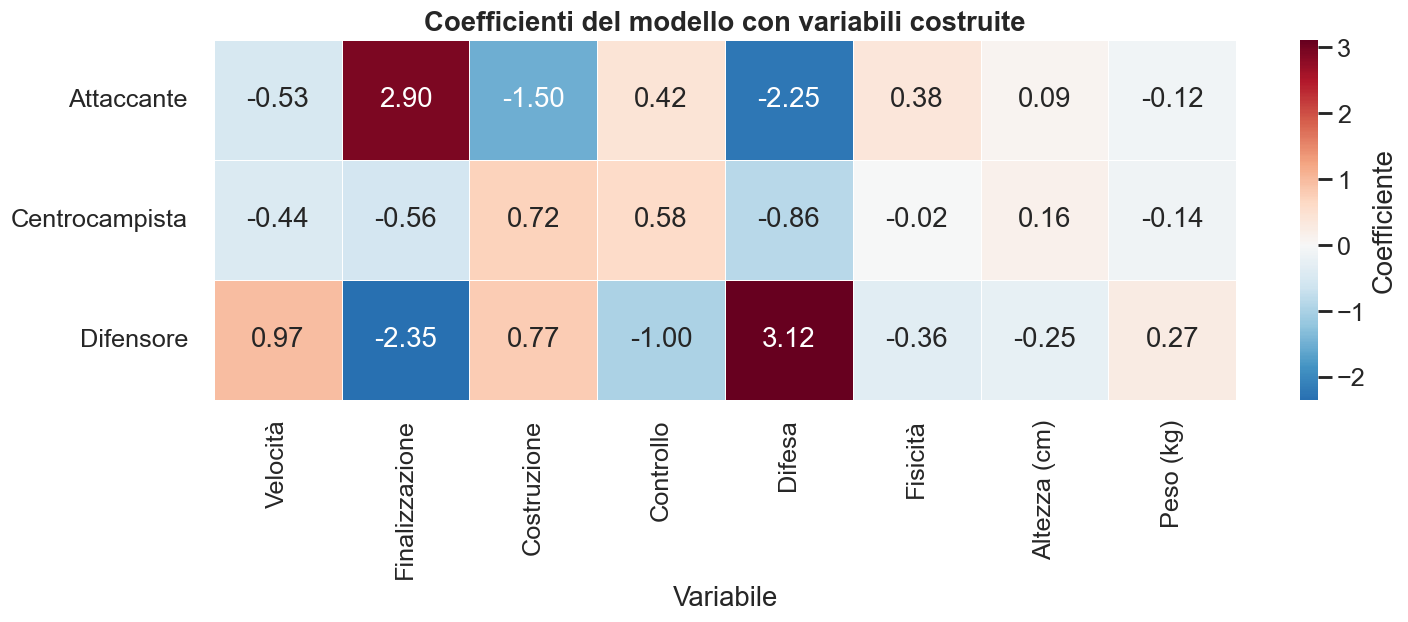

In [14]:
enriched_coefficient_table = pd.DataFrame(
    enriched_model.coef_,
    index=enriched_model.classes_,
    columns=enriched_indicator_names,
).reindex(CLASS_ORDER)

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(
    enriched_coefficient_table,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    linewidths=0.5,
    cbar_kws={'label': 'Coefficiente'},
    ax=ax,
)
ax.set_title('Coefficienti del modello con variabili costruite')
ax.set_xlabel('Variabile')
ax.set_ylabel('')
ax.tick_params(axis='y', rotation=0, pad=8)
fig.tight_layout()
fig.savefig(
    FIG_DIR / '13_coefficienti_feature_engineering.png',
    dpi=300,
    bbox_inches='tight',
)
plt.show()


### Lettura dell'esperimento

La rappresentazione completa ottiene **0,8770 di accuracy** e **0,8694 di F1 macro**. Riducendo le 29 statistiche a sei indici, l'accuracy scende a **0,8230** e l'F1 macro a **0,8205**. La sintesi elimina quindi circa il 79% delle variabili, ma perde rispettivamente 5,4 e 4,9 punti percentuali nelle due metriche.

La diminuzione suggerisce che le singole abilità contengono differenze utili che la loro media nasconde. Due giocatori possono, per esempio, avere lo stesso indice difensivo pur presentando combinazioni diverse di intercettazioni, marcatura e contrasti. La regressione sulle 29 statistiche riesce a sfruttare queste differenze, mentre quella sui sei indici non può farlo.

L'aggiunta di altezza e peso produce valori quasi identici: **0,8232 di accuracy** e **0,8206 di F1 macro**. In questa impostazione le due caratteristiche fisiche non recuperano l'informazione persa durante l'aggregazione.

Il feature engineering rimane comunque utile come esperimento di riduzione e interpretazione: il modello diventa più compatto e i profili dei ruoli sono più facili da descrivere, ma per la previsione finale è preferibile conservare le 29 statistiche originali. Il risultato mostra anche che costruire nuove variabili non garantisce automaticamente prestazioni migliori.


## 9. Conclusioni

- Il riferimento basato sulla classe più frequente raggiunge circa il 42% di accuracy.
- La regressione logistica e Random Forest superano l'87% di accuracy e ottengono un F1-score macro vicino a 0,87.
- Gli errori riguardano soprattutto il confine fra centrocampisti e giocatori offensivi o difensivi. La confusione diretta fra attaccanti e difensori è molto rara.
- Random Forest ottiene il valore più alto sul test set, ma mostra anche una maggiore differenza fra training e test.
- La regressione logistica offre prestazioni quasi equivalenti e permette una lettura più immediata dell'influenza delle caratteristiche.
- Il feature engineering riduce le 29 statistiche a sei indicatori interpretabili, ma porta l'accuracy da 0,8770 a 0,8230 e l'F1 macro da 0,8694 a 0,8205. Altezza e peso non producono un miglioramento apprezzabile.

I risultati rimangono elevati anche dopo aver escluso tutte le variabili derivate dalle posizioni. La classificazione dipende quindi effettivamente dalle caratteristiche tecniche dei giocatori e non da informazioni che anticipano direttamente il ruolo. L'esperimento di feature engineering evidenzia un compromesso chiaro: gli indici sintetici facilitano la lettura dei profili, mentre le statistiche separate conservano più informazione e sono preferibili per il modello predittivo finale.


In [15]:
print('RISULTATI PRINCIPALI')
print('-' * 60)
for model_name in metrics_table.index:
    print(
        f'{model_name}: '
        f'accuracy test={metrics_table.loc[model_name, "Accuracy test"]:.4f}, '
        f'F1 macro={metrics_table.loc[model_name, "F1-score macro"]:.4f}'
    )

print('\nCONFRONTO DELLE RAPPRESENTAZIONI')
print('-' * 60)
for representation in feature_engineering_table.index:
    print(
        f'{representation}: '
        f'variabili={feature_engineering_table.loc[representation, "Numero variabili"]:.0f}, '
        f'accuracy={feature_engineering_table.loc[representation, "Accuracy"]:.4f}, '
        f'F1 macro={feature_engineering_table.loc[representation, "F1-score macro"]:.4f}'
    )


RISULTATI PRINCIPALI
------------------------------------------------------------
Riferimento: accuracy test=0.4197, F1 macro=0.1971
Regressione logistica: accuracy test=0.8770, F1 macro=0.8694
Random Forest: accuracy test=0.8820, F1 macro=0.8713

CONFRONTO DELLE RAPPRESENTAZIONI
------------------------------------------------------------
29 statistiche originali: variabili=29, accuracy=0.8770, F1 macro=0.8694
6 indici tecnici: variabili=6, accuracy=0.8230, F1 macro=0.8205
6 indici + altezza/peso: variabili=8, accuracy=0.8232, F1 macro=0.8206
